In [2]:
!pip install -q roboflow

from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
project = rf.workspace("custom-3w4p0").project("conveyor-belt-object-detection-ehaa8")
version = project.version(9)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to conveyor-belt-object-detection-9 in yolov8:: 100%|██████████| 5712/5712 [00:01<00:00, 4865.30it/s]


Dataset directory: /content/conveyor-belt-object-detection-9
Classes: ['anomaly', 'glass', 'metal', 'plastic']
Image count per split: {'train': 2484, 'valid': 244, 'test': 122}


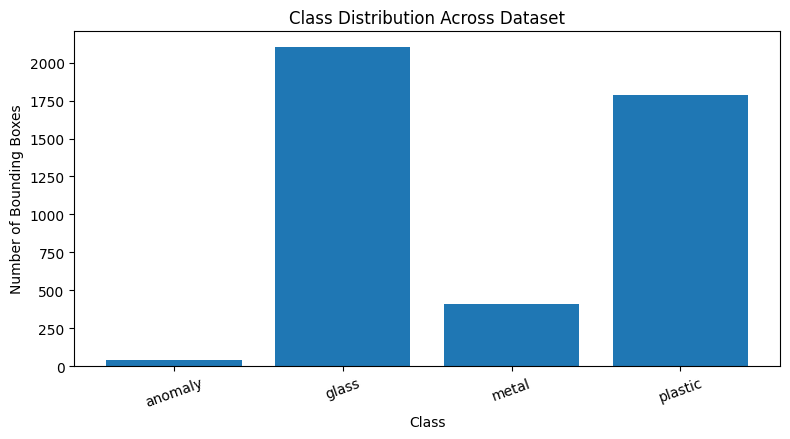

Instance count per class: {'anomaly': 42, 'glass': 2102, 'metal': 407, 'plastic': 1789}
Image resolutions (W, H) found: {(640, 640)}
Done! Outputs saved to eda_outputs/


In [3]:
import os
import glob
import yaml
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Use the dataset folder path from the downloaded `dataset` object
dataset_dir = dataset.location if "dataset" in globals() else "/content/conveyor-belt-object-detection-9"
print("Dataset directory:", dataset_dir)

# 1. Read class names from data.yaml
yaml_path = os.path.join(dataset_dir, "data.yaml")
with open(yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg["names"]
if isinstance(class_names, dict):
    class_names = [class_names[i] for i in sorted(class_names.keys())]

print("Classes:", class_names)

# 2. Count images per split ('train', 'valid'/'val', 'test')
splits = ["train", "valid", "val", "test"]
split_counts = {}
active_splits = []

for sp in splits:
    img_dir = os.path.join(dataset_dir, sp, "images")
    if os.path.exists(img_dir):
        imgs = glob.glob(os.path.join(img_dir, "*.*"))
        split_counts[sp] = len(imgs)
        active_splits.append(sp)

print("Image count per split:", split_counts)

# 3. Count bounding box instances per class & inspect image resolutions
class_counts = {name: 0 for name in class_names}
resolutions = set()

for sp in active_splits:
    img_dir = os.path.join(dataset_dir, sp, "images")
    lbl_dir = os.path.join(dataset_dir, sp, "labels")
    for img_path in glob.glob(os.path.join(img_dir, "*.*")):
        with Image.open(img_path) as im:
            resolutions.add(im.size)  # (width, height)
        base = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(lbl_dir, base + ".txt")
        if os.path.exists(lbl_path):
            with open(lbl_path, "r") as lf:
                for line in lf:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        cls_id = int(float(parts[0]))
                        if 0 <= cls_id < len(class_names):
                            class_counts[class_names[cls_id]] += 1

os.makedirs("eda_outputs", exist_ok=True)

# Plot class distribution bar chart
plt.figure(figsize=(8, 4.5))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("Class Distribution Across Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("eda_outputs/class_distribution.png", dpi=200)
plt.show()

print("Instance count per class:", class_counts)
print("Image resolutions (W, H) found:", resolutions)

# 4. Save 6 sample images with ground-truth bounding boxes
sample_source = os.path.join(dataset_dir, "train", "images")
sample_imgs = glob.glob(os.path.join(sample_source, "*.*"))[:6]

for idx, img_path in enumerate(sample_imgs, 1):
    im = Image.open(img_path).convert("RGB")
    w, h = im.size
    draw = ImageDraw.Draw(im)
    base = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(dataset_dir, "train", "labels", base + ".txt")
    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as lf:
            for line in lf:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cls_id = int(float(parts[0]))
                    xc, yc, bw, bh = map(float, parts[1:5])
                    x1 = (xc - bw / 2) * w
                    y1 = (yc - bh / 2) * h
                    x2 = (xc + bw / 2) * w
                    y2 = (yc + bh / 2) * h
                    label = class_names[cls_id] if 0 <= cls_id < len(class_names) else str(cls_id)
                    draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
                    draw.text((x1 + 4, max(0, y1 - 14)), label, fill="yellow")
    im.save(f"eda_outputs/sample_{idx}.jpg")

print("Done! Outputs saved to eda_outputs/")